# 02 ? Understand the non-private baseline

We train an ordinary neural network to predict the existing Folktables employment label. This is the comparison model for later DP-SGD runs. ESP has been removed; the input has 77 numerical columns. Race/sex are used for auditing, not direct inputs. Neither LFR nor equalized-odds rules are applied yet.

The network is **77 inputs ? 64 ReLU units ? 32 ReLU units ? 1 output**. A sigmoid converts the output into a positive-label probability. A score of at least 0.5 predicts Y=1. Binary cross-entropy penalizes inaccurate probabilities; ordinary SGD updates the weights to reduce that loss.

This notebook reads the completed single-seed development run. The test set remains untouched. Select the project's .venv kernel and run from the top.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'proposal.md').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
RUN=ROOT/'results/baseline'
summary=json.loads((RUN/'summary.json').read_text())
display(pd.Series(summary['config'],name='setting').to_frame())
print(summary['scope'])

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\CiciA\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


,setting
seed,285
hidden_sizes,"[64, 32]"
epochs,20
batch_size,512
learning_rate,0.05
momentum,0.0
threshold,0.5
cpu_threads,4
output_dir,results/baseline


single-seed non-private development baseline; not final test results


## 1. What was trained?

The configuration records the seed, 20 full passes through training data (epochs), batch size 512, learning rate 0.05, and ordinary SGD without momentum. We keep the final epoch instead of searching for the best checkpoint. These are starting settings, not optimized conclusions.

To deliberately rerun training, use the following cell after uncommenting its last line. It overwrites this run's outputs; changing the JSON configuration changes the experiment.

In [2]:
from src.baseline import train
# To rerun: uncomment the next line.
# summary = train(ROOT/'configs/baseline.json')

## 2. Did learning work?

Training loss measures prediction error on training records; development loss uses separate records. Lower loss is better. Development accuracy is the fraction of correct binary predictions. It is not itself a fairness guarantee. Compare the learned model against always guessing the most common TRAINING label.

,epoch,train_loss,development_loss,development_accuracy
0,1,0.670329,0.636418,0.675192
1,2,0.589222,0.552822,0.724557
2,3,0.541254,0.530791,0.749339
3,4,0.526765,0.519171,0.758657
4,5,0.517099,0.510650,0.762424
5,6,0.511027,0.508361,0.762127
6,7,0.507149,0.502324,0.765497
7,8,0.504796,0.502056,0.766092
8,9,0.502779,0.500479,0.763614
9,10,0.501142,0.496614,0.768107


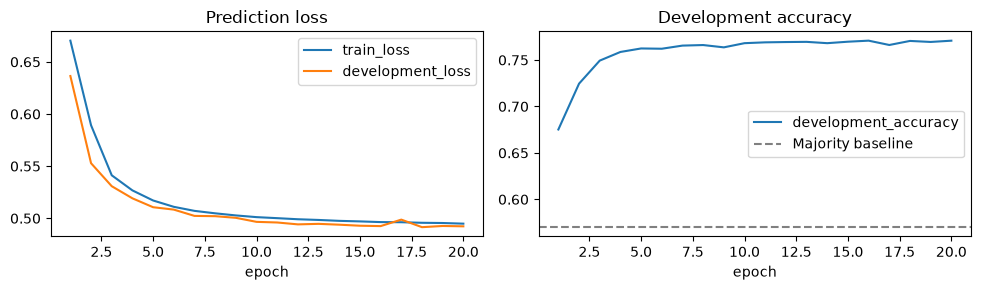

,n,accuracy,balanced_accuracy,selection_rate
MLP,30264,0.770784,0.757322,0.632137
Always-majority,30264,0.570050,0.500000,1.000000


In [3]:
history=pd.read_csv(RUN/'history.csv')
display(history)
fig,axes=plt.subplots(1,2,figsize=(10,3))
history.plot(x='epoch',y=['train_loss','development_loss'],ax=axes[0],title='Prediction loss')
history.plot(x='epoch',y='development_accuracy',ax=axes[1],title='Development accuracy')
axes[1].axhline(summary['majority']['accuracy'],color='gray',linestyle='--',label='Majority baseline')
axes[1].legend();plt.tight_layout();plt.show()
display(pd.DataFrame([summary['overall'],summary['majority']],index=['MLP','Always-majority'])[['n','accuracy','balanced_accuracy','selection_rate']])

## 3. How do groups perform?

These tables contain model results, unlike the label-base-rate tables in notebook 01. Accuracy is correctness within each group. TPR/FPR measure positive detection and false alarms; PPV/NPV measure reliability of positive/negative predictions. Rates are on a 0?1 scale: 0.8 means 80%.

Inspect n and the confusion-matrix counts before interpreting gaps. min_conditional_count is the smallest denominator among the four conditional rates; values below 30 are flagged for discussion.

In [4]:
groups=pd.read_csv(RUN/'group_metrics.csv')
groups['small_denominator']=groups.min_conditional_count.lt(30)
columns=['group','n','tp','tn','fp','fn','accuracy','tpr','fpr','ppv','npv','small_denominator']
print('SEX: 1=male; 2=female')
display(groups.loc[groups.attribute.eq('SEX'),columns])
print('RAC1P: original Census race codes; see the data-processing log')
display(groups.loc[groups.attribute.eq('RAC1P'),columns])
display(pd.DataFrame(summary['gaps']).T)

SEX: 1=male; 2=female


,group,n,tp,tn,fp,fn,accuracy,tpr,fpr,ppv,npv,small_denominator
0,1,14826,7777,4155,1547,1347,0.804802,0.852367,0.271308,0.834084,0.755180,False
1,2,15438,6946,4449,2861,1182,0.738114,0.854577,0.391382,0.708270,0.790091,False


RAC1P: original Census race codes; see the data-processing log


,group,n,tp,tn,fp,fn,accuracy,tpr,fpr,ppv,npv,small_denominator
2,1,18889,8977,5630,2549,1733,0.773307,0.838189,0.311652,0.778848,0.764634,False
3,2,1500,613,583,182,122,0.797333,0.834014,0.237908,0.771069,0.826950,False
4,3,202,73,66,46,17,0.688119,0.811111,0.410714,0.613445,0.795181,False
5,4,2,0,2,0,0,1.000000,NaN,0.000000,NaN,1.000000,True
6,5,81,39,26,8,8,0.802469,0.829787,0.235294,0.829787,0.764706,False
7,6,5017,2635,1217,850,315,0.767790,0.893220,0.411224,0.756098,0.794386,False
8,7,95,54,26,11,4,0.842105,0.931034,0.297297,0.830769,0.866667,False
9,8,3299,1720,755,570,254,0.750227,0.871327,0.430189,0.751092,0.748266,False
10,9,1179,612,299,192,76,0.772689,0.889535,0.391039,0.761194,0.797333,False


,accuracy_gap,independence,tpr_gap,fpr_gap,separation,ppv_gap,npv_gap,sufficiency
RAC1P,0.311881,0.694638,NaN,0.430189,NaN,NaN,0.251734,NaN
RAC1P_SEX,0.317834,0.713161,NaN,0.518564,NaN,NaN,0.277778,NaN
SEX,0.066689,0.006355,0.002209,0.120073,0.120073,0.125814,0.034911,0.125814


## 4. What can we conclude now?

Independence is the selection-rate gap. Separation is the larger of TPR/FPR gaps. Sufficiency is the larger of PPV/NPV gaps. A missing value means at least one required group rate is undefined; it is not zero disparity. Small-group estimates can be very noisy.

This is one seed, one non-private model, and development data. It establishes a working reference; it cannot tell us what DP will change. Next we will train the same prediction task with DP-SGD at several privacy budgets, using these evaluation functions again.

Write your notes:
- Does the MLP improve on majority guessing?
- Does development loss track training loss?
- Which groups have unreliable denominators?
- Which settings should be kept fixed for the privacy pilots?